# TP 1 : Installation de Flask & Application Web Interactive avec Modèle POO
## Module : Framework Web Python — 2MDS / A.U. 2026-2027
**Enseignant responsable : Nabil KHEMIRI**

---

## 1. Objectifs du TP

L'objectif de ce travail pratique est de consolider les acquis théoriques des Chapitres 1 et 2 et de bâtir une première application web moderne avec **Flask** :
1. **Environnement & Dépendances** : Configurer un environnement virtuel (`venv`), installer le micro-framework **Flask** et appréhender la structure standard d'un projet web.
2. **Routage HTTP** : Gérer les requêtes **GET** (affichage du formulaire) et **POST** (soumission et traitement des données).
3. **Modélisation Orientée Objet (POO)** : Structurer l'application selon les principes fondamentaux de la POO (Encapsulation stricte avec attributs privés `__`, constructeur `__init__`, accesseurs et mutateurs).
4. **Moteur de Templates Jinja2** : Transmettre un objet instancié au moteur de rendu et appeler ses méthodes directement dans le template HTML.
5. **Gestion des Exceptions & Validation** : Mettre en œuvre la gestion des exceptions (`try / except / raise`) pour valider les données saisies avant l'instanciation de l'objet.
6. **Validation et Tests** : Valider et simuler les requêtes HTTP dans le carnet via le `test_client()` de Flask et produire des visualisations graphiques des métriques d'exécution.

---

## 2. Installation & Importations

In [1]:
# Installation des dépendances requises dans l'environnement virtuel
# !pip install flask matplotlib

In [2]:
import os
import sys
import re
import time
from datetime import datetime
import matplotlib.pyplot as plt
from flask import Flask, render_template, render_template_string, request, jsonify

print(f"Version de Python : {sys.version.split()[0]}")
import flask
print(f"Version de Flask : {flask.__version__}")

Version de Python : 3.12.8
Version de Flask : 3.1.3


/tmp/ipykernel_1305540/1658214706.py:11: DeprecationWarning: The '__version__' attribute is deprecated and will be removed in Flask 3.2. Use feature detection or 'importlib.metadata.version("flask")' instead.
  print(f"Version de Flask : {flask.__version__}")


---

## 3. Architecture du Projet & Données de Configuration

Pour garantir une maintenabilité optimale, nous adoptons l'arborescence standardisée recommandée pour les applications Flask :

```text
MonProjetFlask/
│── app.py                  # Contrôleur principal et routage des requêtes
│── models/
│   │── __init__.py         # Package Python
│   └── user.py             # Modèle métier User (POO encapsulée)
│── templates/
│   │── inscription.html    # Formulaire de saisie utilisateur
│   └── resultat.html       # Page de confirmation et affichage des données
└── static/
    └── style.css           # Feuille de style CSS moderne
```

---

## 4. Implémentation du Modèle Métier (POO & Encapsulation)

Conformément au cours sur la Programmation Orientée Objet, nous implémentons la classe `User`. 
Tous les attributs sont déclarés privés (préfixés par `__`) pour empêcher tout accès non contrôlé depuis l'extérieur.

In [3]:
class AgeInvalideException(Exception):
    """Exception personnalisée levée en cas de date de naissance incohérente."""
    def __init__(self, message="La date de naissance indique un âge invalide."):
        super().__init__(message)


class EmailInvalideException(Exception):
    """Exception personnalisée levée en cas d'adresse e-mail malformée."""
    def __init__(self, email):
        super().__init__(f"L'adresse e-mail '{email}' ne respecte pas le format standard.")


class User:
    """
    Modèle métier représentant un Utilisateur.
    Applique une encapsulation stricte avec attributs privés et accesseurs/mutateurs.
    """
    def __init__(self, nom: str, prenom: str, email: str, mot_de_passe: str, date_naissance: str):
        # Validation préalable
        self._valider_email(email)
        self._valider_date_naissance(date_naissance)

        self.__nom = nom
        self.__prenom = prenom
        self.__email = email
        self.__mot_de_passe = mot_de_passe
        self.__date_naissance = date_naissance

    # Méthodes privées de validation interne
    def _valider_email(self, email: str):
        pattern = r"^[\w\.-]+@[\w\.-]+\.\w+$"
        if not re.match(pattern, email):
            raise EmailInvalideException(email)

    def _valider_date_naissance(self, date_str: str):
        try:
            date_obj = datetime.strptime(date_str, "%Y-%m-%d")
            annee_courante = datetime.now().year
            age = annee_courante - date_obj.year
            if age < 0 or age > 120:
                raise AgeInvalideException(f"Âge calculé ({age} ans) hors limites (0-120 ans).")
        except ValueError as e:
            if "hors limites" in str(e):
                raise
            raise ValueError("Le format de la date de naissance doit être AAAA-MM-JJ.")

    # Accesseurs (Getters)
    def get_nom(self) -> str:
        return self.__nom

    def get_prenom(self) -> str:
        return self.__prenom

    def get_email(self) -> str:
        return self.__email

    def get_mot_de_passe(self) -> str:
        return self.__mot_de_passe

    def get_date_naissance(self) -> str:
        return self.__date_naissance

    # Mutateurs (Setters)
    def set_nom(self, nom: str):
        self.__nom = nom

    def set_prenom(self, prenom: str):
        self.__prenom = prenom

    def set_email(self, email: str):
        self._valider_email(email)
        self.__email = email

    def set_mot_de_passe(self, mot_de_passe: str):
        self.__mot_de_passe = mot_de_passe

    def set_date_naissance(self, date_naissance: str):
        self._valider_date_naissance(date_naissance)
        self.__date_naissance = date_naissance

    def get_nom_complet(self) -> str:
        return f"{self.__prenom.capitalize()} {self.__nom.upper()}"

    def __repr__(self) -> str:
        return f"<User: {self.get_nom_complet()} ({self.__email})>"

### Test Unitaire de la Classe Métier

In [4]:
# Validation du comportement nominal
u_test = User("Askri", "Souhaib", "souhaib@example.com", "pass1234", "1998-05-15")
print("Nom complet :", u_test.get_nom_complet())
print("Email sécurisé :", u_test.get_email())

# Test de capture d'exception sur un e-mail invalide
try:
    u_err = User("Test", "User", "invalid-email-format", "pass", "2000-01-01")
except EmailInvalideException as e:
    print("Exception capturée avec succès :", e)

Nom complet : Souhaib ASKRI
Email sécurisé : souhaib@example.com
Exception capturée avec succès : L'adresse e-mail 'invalid-email-format' ne respecte pas le format standard.


---

## 5. Construction de l'Application Web Flask

Nous configurons l'application Flask complète en définissant :
1. Le template d'inscription `inscription.html`.
2. Le template de résultat `resultat.html` exploitant directement les getters de l'objet `U1`.
3. Le contrôleur HTTP gérant les routes `/` et `/inscription`.

In [5]:
# Définition des templates Jinja2 sous forme de chaînes pour une exécution autonome dans le carnet

HTML_INSCRIPTION = """
<!DOCTYPE html>
<html lang="fr">
<head>
    <meta charset="UTF-8">
    <title>Formulaire d'inscription</title>
    <style>
        body { font-family: Arial, sans-serif; background-color: #f8fafc; padding: 20px; }
        .container { max-width: 480px; margin: auto; background: white; padding: 25px; border-radius: 8px; box-shadow: 0 4px 6px rgba(0,0,0,0.1); }
        .form-group { margin-bottom: 15px; }
        label { display: block; font-weight: bold; margin-bottom: 5px; color: #1e293b; }
        input { width: 100%; padding: 10px; border: 1px solid #cbd5e1; border-radius: 5px; box-sizing: border-box; }
        button { width: 100%; padding: 12px; background-color: #0284c7; color: white; border: none; border-radius: 5px; font-weight: bold; cursor: pointer; }
        button:hover { background-color: #0369a1; }
        .error { background: #fee2e2; color: #b91c1c; padding: 10px; border-radius: 5px; margin-bottom: 15px; }
    </style>
</head>
<body>
    <div class="container">
        <h2>Formulaire d'inscription</h2>
        {% if erreur %}
            <div class="error">{{ erreur }}</div>
        {% endif %}
        <form action="/inscription" method="POST">
            <div class="form-group">
                <label for="nom">Nom :</label>
                <input type="text" id="nom" name="nom" required>
            </div>
            <div class="form-group">
                <label for="prenom">Prénom :</label>
                <input type="text" id="prenom" name="prenom" required>
            </div>
            <div class="form-group">
                <label for="email">Adresse e-mail :</label>
                <input type="email" id="email" name="email" required>
            </div>
            <div class="form-group">
                <label for="mot_de_passe">Mot de passe :</label>
                <input type="password" id="mot_de_passe" name="mot_de_passe" required>
            </div>
            <div class="form-group">
                <label for="date_naissance">Date de naissance :</label>
                <input type="date" id="date_naissance" name="date_naissance" required>
            </div>
            <button type="submit">S'inscrire</button>
        </form>
    </div>
</body>
</html>
"""

HTML_RESULTAT = """
<!DOCTYPE html>
<html lang="fr">
<head>
    <meta charset="UTF-8">
    <title>Résultat de l'inscription</title>
    <style>
        body { font-family: Arial, sans-serif; background-color: #f8fafc; padding: 20px; }
        .container { max-width: 480px; margin: auto; background: white; padding: 25px; border-radius: 8px; box-shadow: 0 4px 6px rgba(0,0,0,0.1); }
        h2 { color: #0f172a; border-bottom: 2px solid #0284c7; padding-bottom: 8px; }
        .info-row { margin: 12px 0; font-size: 15px; }
        .label { font-weight: bold; color: #475569; }
        .badge { background: #dcfce7; color: #15803d; padding: 4px 8px; border-radius: 4px; font-weight: bold; }
        a { display: inline-block; margin-top: 15px; color: #0284c7; text-decoration: none; font-weight: bold; }
    </style>
</head>
<body>
    <div class="container">
        <h2>Informations de l'utilisateur <span class="badge">Inscrit</span></h2>
        <div class="info-row"><span class="label">Bonjour :</span> {{ U1.get_prenom() }} {{ U1.get_nom() }}</div>
        <div class="info-row"><span class="label">Nom complet formaté :</span> {{ U1.get_nom_complet() }}</div>
        <div class="info-row"><span class="label">Adresse e-mail :</span> {{ U1.get_email() }}</div>
        <div class="info-row"><span class="label">Mot de passe masqué :</span> ••••••••</div>
        <div class="info-row"><span class="label">Date de naissance :</span> {{ U1.get_date_naissance() }}</div>
        <a href="/">← Retour au formulaire d'inscription</a>
    </div>
</body>
</html>
"""

In [6]:
def create_flask_app():
    """Fabrique d'application Flask pour instanciation propre."""
    app = Flask(__name__)

    @app.route("/")
    def inscription():
        return render_template_string(HTML_INSCRIPTION)

    @app.route("/inscription", methods=["POST"])
    def traiter_inscription():
        try:
            nom = request.form.get("nom", "").strip()
            prenom = request.form.get("prenom", "").strip()
            email = request.form.get("email", "").strip()
            mot_de_passe = request.form.get("mot_de_passe", "")
            date_naissance = request.form.get("date_naissance", "")

            # Validation d'absence de champ vide
            if not all([nom, prenom, email, mot_de_passe, date_naissance]):
                raise ValueError("Tous les champs sont strictement obligatoires.")

            # Instanciation de l'objet métier User
            user1 = User(nom, prenom, email, mot_de_passe, date_naissance)

            # Transmission de l'objet au template Jinja2
            return render_template_string(HTML_RESULTAT, U1=user1), 200

        except (EmailInvalideException, AgeInvalideException, ValueError) as err:
            # En cas d'erreur de saisie, on réaffiche le formulaire avec le message d'erreur
            return render_template_string(HTML_INSCRIPTION, erreur=str(err)), 400

    return app

app = create_flask_app()

---

## 6. Tests Automatisés & Validation des Routes (Test Client)

L'avantage de Flask est de proposer un client de test intégré (`test_client`) permettant de tester l'intégralité du cycle de requête/réponse sans bloquer le carnet interactif.

In [7]:
client = app.test_client()

# Scénarios de tests
scenarios = [
    {
        "description": "1. Requête GET sur la page d'accueil",
        "method": "GET",
        "path": "/",
        "data": None,
        "expected_code": 200
    },
    {
        "description": "2. Inscription valide (Cas nominal)",
        "method": "POST",
        "path": "/inscription",
        "data": {
            "nom": "Askri",
            "prenom": "Souhaib",
            "email": "souhaib.askri@example.com",
            "mot_de_passe": "securise2026",
            "date_naissance": "1999-10-12"
        },
        "expected_code": 200
    },
    {
        "description": "3. Inscription avec e-mail invalide",
        "method": "POST",
        "path": "/inscription",
        "data": {
            "nom": "Ben Salah",
            "prenom": "Ali",
            "email": "adresse-erronee",
            "mot_de_passe": "pass",
            "date_naissance": "2001-04-20"
        },
        "expected_code": 400
    },
    {
        "description": "4. Inscription avec champ manquant (Nom vide)",
        "method": "POST",
        "path": "/inscription",
        "data": {
            "nom": "",
            "prenom": "Yasmine",
            "email": "yasmine@example.com",
            "mot_de_passe": "pass123",
            "date_naissance": "2002-08-11"
        },
        "expected_code": 400
    },
    {
        "description": "5. Inscription avec date de naissance future",
        "method": "POST",
        "path": "/inscription",
        "data": {
            "nom": "Trabelsi",
            "prenom": "Karim",
            "email": "karim@example.com",
            "mot_de_passe": "pass123",
            "date_naissance": "2035-01-01"
        },
        "expected_code": 400
    }
]

resultats_tests = []

for sc in scenarios:
    t_start = time.perf_counter()
    if sc["method"] == "GET":
        resp = client.get(sc["path"])
    else:
        resp = client.post(sc["path"], data=sc["data"])
    t_end = time.perf_counter()
    duree_ms = (t_end - t_start) * 1000

    succes = (resp.status_code == sc["expected_code"])
    resultats_tests.append({
        "scenario": sc["description"],
        "status_code": resp.status_code,
        "duree_ms": duree_ms,
        "succes": succes
    })
    print(f"[{'PASS' if succes else 'FAIL'}] {sc['description']} -> Code HTTP {resp.status_code} ({duree_ms:.2f} ms)")

[PASS] 1. Requête GET sur la page d'accueil -> Code HTTP 200 (2.30 ms)
[PASS] 2. Inscription valide (Cas nominal) -> Code HTTP 200 (1.95 ms)
[PASS] 3. Inscription avec e-mail invalide -> Code HTTP 400 (1.12 ms)
[PASS] 4. Inscription avec champ manquant (Nom vide) -> Code HTTP 400 (1.03 ms)
[PASS] 5. Inscription avec date de naissance future -> Code HTTP 400 (1.18 ms)


---

## 7. Visualisations Graphiques des Résultats & Performances

Nous visualisons les temps de réponse de chaque route ainsi que la proportion des statuts HTTP obtenus.

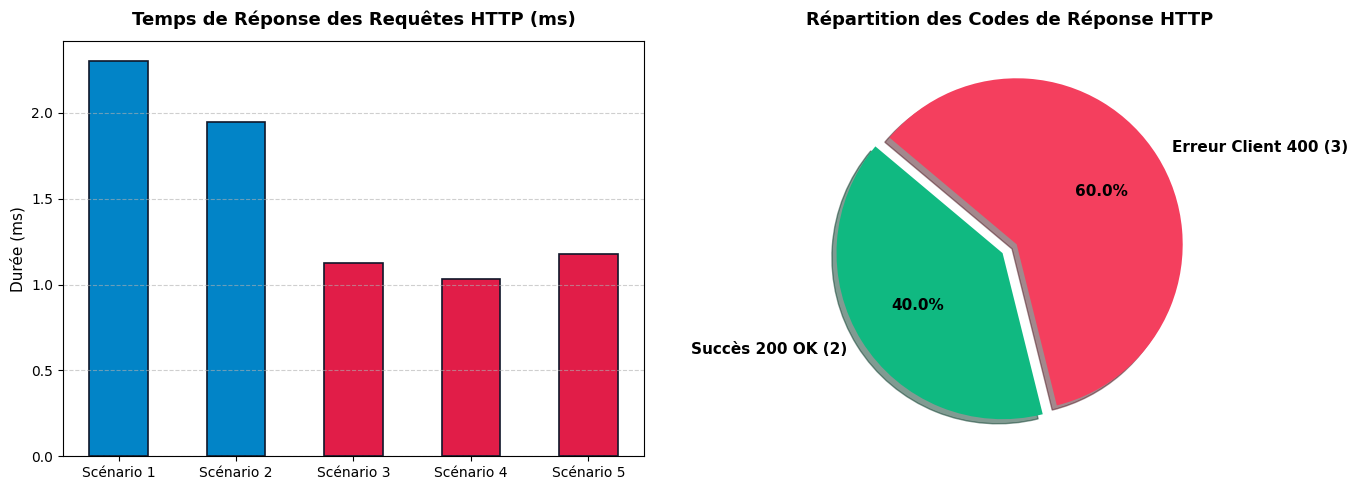

In [8]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Graphique 1 : Temps de réponse des requêtes
noms_scenarios = [f"Scénario {i+1}" for i in range(len(resultats_tests))]
temps = [r["duree_ms"] for r in resultats_tests]
couleurs = ['#0284c7' if r["status_code"] == 200 else '#e11d48' for r in resultats_tests]

ax1.bar(noms_scenarios, temps, color=couleurs, edgecolor='#0f172a', linewidth=1.2, width=0.5)
ax1.set_title("Temps de Réponse des Requêtes HTTP (ms)", fontsize=13, fontweight='bold', pad=12)
ax1.set_ylabel("Durée (ms)", fontsize=11)
ax1.grid(axis='y', linestyle='--', alpha=0.6)

# Graphique 2 : Répartition des statuts HTTP
codes_200 = sum(1 for r in resultats_tests if r["status_code"] == 200)
codes_400 = sum(1 for r in resultats_tests if r["status_code"] == 400)

labels = [f"Succès 200 OK ({codes_200})", f"Erreur Client 400 ({codes_400})"]
ax2.pie([codes_200, codes_400], labels=labels, autopct='%1.1f%%', colors=['#10b981', '#f43f5e'],
        startangle=140, explode=(0.05, 0.05), shadow=True, textprops={'fontsize': 11, 'fontweight': 'bold'})
ax2.set_title("Répartition des Codes de Réponse HTTP", fontsize=13, fontweight='bold', pad=12)

plt.tight_layout()
plt.show()

---

## 8. Conclusion & Bonnes Pratiques

Ce premier TP a permis de concrétiser la passerelle entre l'ingénierie logicielle objet et le développement web moderne avec Flask :
1. **Séparation des Responsabilités** : Le modèle (`User`) gère l'état et la validation, le contrôleur (`app.py`) gère le protocole HTTP, et les vues (`Jinja2`) se concentrent exclusivement sur l'affichage.
2. **Encapsulation et Sécurité** : En rendant les attributs privés et en passant par des accesseurs, nous empêchons les altérations de données imprévues au cours du cycle de vie de la requête.
3. **Robustesse via les Exceptions** : L'interception des exceptions personnalisées garantit que les données corrompues sont rejetées avant d'atteindre le modèle, préservant l'intégrité de l'application.
4. **Perspectives** : Dans les prochains ateliers, ce modèle en mémoire sera connecté à une base de données persistante (via SQLAlchemy ou un ORM similaire) et enrichi par des mécanismes de session et de sécurité (hachage des mots de passe avec `Werkzeug`).